In [1]:
# -----------------------------------------------------------------------
# Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, pearsonr, qmc, skew
from scipy.optimize import minimize
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
np.random.seed(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


# ---------------------------------------------------------------- figures
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    })

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



Dataset: n=50 observations (40 initial + 10 queried), d=8 input dimensions
Input range per dimension  : min=[0.009 0.003 0.023 0.009 0.01  0.022 0.036 0.   ]
                             max=[0.986 0.974 0.999 0.903 1.    0.99  0.993 1.   ]
Output range: [5.592, 9.997], mean=8.229, std=1.190



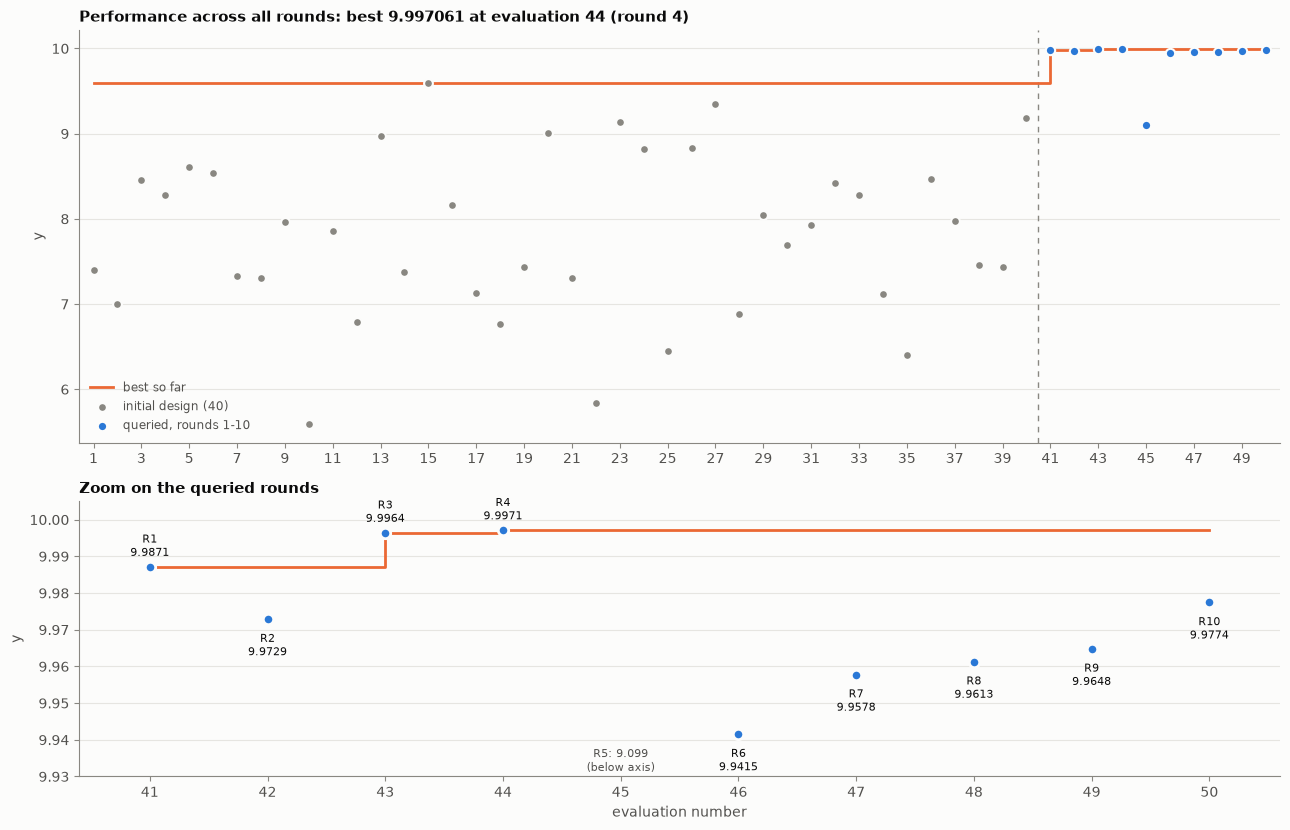

In [2]:
# --------------------------------------------------------------------- #
# DATA
# --------------------------------------------------------------------- #
X = np.load('..\Function_8_Data\Week_11_Data/F8_Week_11_inputs.npy')
y = np.load('..\Function_8_Data\Week_11_Data/F8_Week_11_outputs.npy')
n, d = X.shape
N_INITIAL = 40   
print(f"Dataset: n={n} observations ({N_INITIAL} initial + {n - N_INITIAL} queried), d={d} input dimensions")
print(f"Input range per dimension  : min={X.min(axis=0).round(3)}")
print(f"                             max={X.max(axis=0).round(3)}")
print(f"Output range: [{y.min():.3f}, {y.max():.3f}], mean={y.mean():.3f}, std={y.std():.3f}\n")

#--------------------------------------------------------------------------
# Fig 1: performance across all rounds
#--------------------------------------------------------------------------
best = int(np.argmax(y))
xb = X[best]
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(13, 8.4), height_ratios=[3, 2])

ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=PAL[1], lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=40, color=MUTED, edgecolor=SURFACE, linewidth=1.5, label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=45, color=PAL[0], edgecolor=SURFACE, linewidth=1.5, label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
ax.set_xticks(idx[::2]); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y[best]:.6f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower left", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=PAL[1], lw=2, zorder=2)
for i in q:
    if y[i] >= 9.9:
        az.scatter(idx[i], y[i], s=56, color=PAL[0], edgecolor=SURFACE, linewidth=2, zorder=3)
        az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.4f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] else -26),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
    else:
        az.annotate(f"R{i - N_INITIAL + 1}: {y[i]:.3f}\n(below axis)", (idx[i], 9.93), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
az.set_ylim(9.93, 10.005); az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds")
fig.tight_layout()

Skewness of y: -0.078


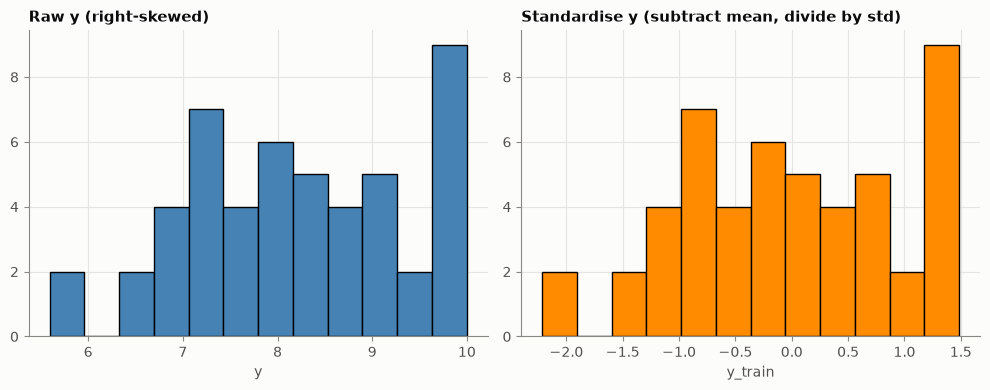

In [3]:
# --------------------------------------------------------------------- #
# DATA TRANSFORMATION
# --------------------------------------------------------------------- #
# INPUTS
# ------
# All 8 columns already lie in (a numerical approximation of) [0, 1].

X_train = X.copy()
bounds = np.array([[0.0, 1.0]] * d)  # search domain for the acquisition optimiser

# OUTPUTS
# -------
# y ranges from ~5.6 to ~10.0 with a non-zero mean (~7.9) and no obvious
# skew/heavy tail (a quick skewness check below confirms this). 
# Standardise y (subtract mean, divide by std) before fitting.
# Convert GP predictions back to the original scale for reporting/plotting.

from scipy.stats import skew
print(f"Skewness of y: {skew(y):.3f}")

y_mean, y_std = y.mean(), y.std()
y_train = (y - y_mean) / y_std

def unstandardise(mu_s, sigma_s):
    """Map standardised GP posterior mean/std back to the original y scale."""
    return mu_s * y_std + y_mean, sigma_s * y_std

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y, bins=12, color="steelblue", edgecolor="k")
axes[0].set_title("Raw y (right-skewed)")
axes[0].set_xlabel("y")
axes[1].hist(y_train, bins=12, color="darkorange", edgecolor="k")
axes[1].set_title("Standardise y (subtract mean, divide by std)")
axes[1].set_xlabel("y_train")
plt.tight_layout()

In [4]:
# --------------------------------------------------------------------- #
# CORRELATION
# --------------------------------------------------------------------- #
print("Marginal (linear) correlation of each input dimension with y:")
corrs = []
for j in range(d):
    r, _ = pearsonr(X_train[:, j], y)
    corrs.append(r)
    print(f"  x{j+1}: r = {r:+.3f}")
corrs = np.array(corrs)
print()


Marginal (linear) correlation of each input dimension with y:
  x1: r = -0.748
  x2: r = -0.391
  x3: r = -0.743
  x4: r = -0.320
  x5: r = +0.194
  x6: r = +0.081
  x7: r = -0.558
  x8: r = +0.175



In [5]:
# --------------------------------------------------------------------- #
# ARD vs Isotropic
# --------------------------------------------------------------------- #
# SURROGATE MODEL: Gaussian Process, Matern-5/2 kernel
# --------------------------------------------------------------------- #


def fit(yy, ard):
    t = (yy - yy.mean()) / yy.std()
    k = (ConstantKernel(1.0, (1e-2, 1e2)) * 
         Matern(length_scale=np.ones(d) if ard else 1.0, length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-3, (1e-6, 1e-1)))
    
    return GaussianProcessRegressor(kernel=k, alpha=1e-8, n_restarts_optimizer=15,
                                    random_state=SEED).fit(X, t), yy.mean(), yy.std()

def loo(model, yy):
    gp, m0, s0 = model
    t = (yy - m0) / s0
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, alpha=1e-8).fit(X[keep], t[keep])
        a, s = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0] * s0 + m0, s[0] * s0
    return mu, sd


runs = {}
print("\nMODELS (LOO with hyperparameters fixed)")
for label, yy in [ ("corrected", y)]:  
    top = np.argsort(-yy)[:8]
    for ard in (True, False):
        key = f"{'ARD' if ard else 'isotropic'}" #{label}, 
        model = fit(yy, ard)
        mu, sd = loo(model, yy)
        runs[key] = (model, mu, sd, yy)
        ls = np.atleast_1d(model[0].kernel_.k1.k2.length_scale)
        on_bound = [j + 1 for j, v in enumerate(ls) if np.isclose(v, 1e-2, rtol=1e-3) or np.isclose(v, 1e2, rtol=1e-3)]
        r2 = 1 - np.sum((yy - mu) ** 2) / np.sum((yy - yy.mean()) ** 2)
        print(f"  {key:22s} ls={np.round(ls, 3)}  LML={model[0].log_marginal_likelihood_value_:.2f}  "
              f"LOO R2={r2:.3f}  RMSE/std={np.sqrt(np.mean((yy - mu) ** 2)) / yy.std():.3f}  "
              f"top-8 RMSE={np.sqrt(np.mean((yy[top] - mu[top]) ** 2)):.3f}  length-scales on a bound: {on_bound}")

REC = "ARD"
(gp, m0, s0), _, _, _ = runs[REC]
print(f"\nRecommended model ({REC}): {gp.kernel_}")

def pmean(Z):
    return gp.predict(np.atleast_2d(Z)) * s0 + m0

def psd(Z):
    return gp.predict(np.atleast_2d(Z), return_std=True)[1] * s0

f_inc = gp.predict(X).max()
def ei(Z):
    m, s = gp.predict(np.atleast_2d(Z), return_std=True)
    s = np.maximum(s, 1e-12)
    z = (m - f_inc) / s
    return (m - f_inc) * norm.cdf(z) + s * norm.pdf(z)

S = qmc.Sobol(d, seed=1).random(2 ** 15)
def box_argmax(fn, r):
    lo, hi = np.clip(xb - r, 0, 1), np.clip(xb + r, 0, 1)
    Z = np.vstack([lo + S * (hi - lo), X[np.all((X >= lo) & (X <= hi), axis=1)]])
    v = fn(Z); x0 = Z[v.argmax()]
    res = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return res.x if -res.fun >= v.max() else x0

cands = {
    "A: EI ±0.05, week-10 script": np.array([0.149473, 0.148617, 0.183071, 0.103646, 0.835160, 0.563603, 0.141092, 0.617162]),
    "B: EI ±0.05": box_argmax(ei, 0.05),
    "C: EI, full domain": box_argmax(ei, 1.0),
    "D: highest predicted mean, full domain": box_argmax(pmean, 1.0),
    "E: highest predicted mean ±0.02": box_argmax(pmean, 0.02),
}
print(f"\nCANDIDATES ({REC}; best observed {y[best]:.6f}, model at best point {pmean(xb)[0]:.6f})")
for name, xc in cands.items():
    print(f"  {name:44s} x = ({', '.join(f'{v:.6f}' for v in xc)})  dist {np.linalg.norm(xc - xb):.3f}  "
          f"predicted {pmean(xc)[0]:.4f} +/- {psd(xc)[0]:.4f}")


MODELS (LOO with hyperparameters fixed)
  ARD                    ls=[ 6.915  9.834  5.666  9.574 13.794  9.969  7.046 28.541]  LML=30.15  LOO R2=0.999  RMSE/std=0.029  top-8 RMSE=0.014  length-scales on a bound: []
  isotropic              ls=[5.211]  LML=2.70  LOO R2=0.987  RMSE/std=0.114  top-8 RMSE=0.058  length-scales on a bound: []

Recommended model (ARD): 10**2 * Matern(length_scale=[6.91, 9.83, 5.67, 9.57, 13.8, 9.97, 7.05, 28.5], nu=2.5) + WhiteKernel(noise_level=1e-06)

CANDIDATES (ARD; best observed 9.997061, model at best point 9.996805)
  A: EI ±0.05, week-10 script                  x = (0.149473, 0.148617, 0.183071, 0.103646, 0.835160, 0.563603, 0.141092, 0.617162)  dist 0.133  predicted 9.9753 +/- 0.0160
  B: EI ±0.05                                  x = (0.120188, 0.148617, 0.128738, 0.153467, 0.800570, 0.555809, 0.176258, 0.619963)  dist 0.072  predicted 9.9954 +/- 0.0100
  C: EI, full domain                           x = (0.106207, 0.112088, 0.133929, 0.148882, 0.789

Leave-one-out CV: R^2 = 0.999, RMSE = 0.034
Leave-one-out on the queried points (actual - predicted, and claimed std):
  idx40: y = 9.987097  predicted = 9.988118  error = -0.001022  claimed std = 0.003952
  idx41: y = 9.972897  predicted = 9.977662  error = -0.004765  claimed std = 0.010629
  idx42: y = 9.996372  predicted = 9.996140  error = +0.000232  claimed std = 0.001566
  idx43: y = 9.997061  predicted = 9.996524  error = +0.000537  claimed std = 0.001727
  idx44: y = 9.099107  predicted = 9.130061  error = -0.030954  claimed std = 0.118809
  idx45: y = 9.941550  predicted = 9.945433  error = -0.003883  claimed std = 0.026199
  idx46: y = 9.957780  predicted = 9.988836  error = -0.031056  claimed std = 0.031522
  idx47: y = 9.961297  predicted = 9.983006  error = -0.021709  claimed std = 0.022387
  idx48: y = 9.964793  predicted = 9.976938  error = -0.012146  claimed std = 0.017689
  idx49: y = 9.977450  predicted = 9.984068  error = -0.006618  claimed std = 0.013048
  RMSE on t

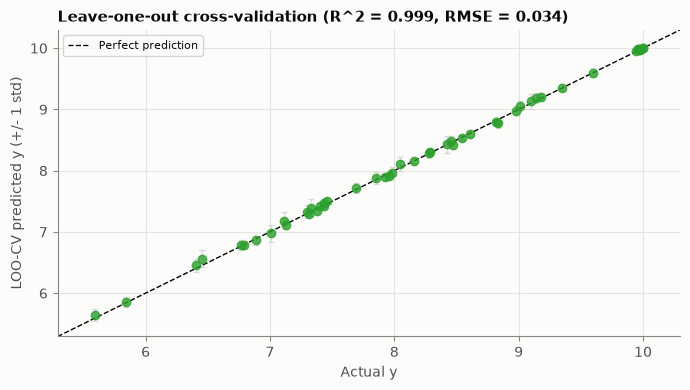

In [6]:

JITTER = 1e-8  # small fixed diagonal jitter for numerical conditioning
loo_pred = np.zeros(n)
loo_std = np.zeros(n)
for i in range(n):
    mask = np.ones(n, dtype=bool)
    mask[i] = False
    gp_loo = GaussianProcessRegressor(
        kernel=gp.kernel_, alpha=JITTER, optimizer=None,  # reuse already-fitted hyperparameters
        normalize_y=False, random_state=SEED
    )
    gp_loo.fit(X_train[mask], y_train[mask])
    mu_s, std_s = gp_loo.predict(X_train[i:i+1], return_std=True)
    mu, std = unstandardise(mu_s, std_s)
    loo_pred[i] = mu[0]
    loo_std[i] = std[0]

ss_res = np.sum((y - loo_pred) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
loo_r2 = 1 - ss_res / ss_tot
rmse = np.sqrt(np.mean((y - loo_pred) ** 2))
print(f"Leave-one-out CV: R^2 = {loo_r2:.3f}, RMSE = {rmse:.3f}")


q_idx = np.arange(N_INITIAL, n)
q_err = y[q_idx] - loo_pred[q_idx]
print("Leave-one-out on the queried points (actual - predicted, and claimed std):")
for i in q_idx:
    print(f"  idx{i}: y = {y[i]:.6f}  predicted = {loo_pred[i]:.6f}  "
          f"error = {y[i] - loo_pred[i]:+.6f}  claimed std = {loo_std[i]:.6f}")
last3 = q_idx[-3:]
print(f"  RMSE on the last 3 queries = {np.sqrt(np.mean((y[last3] - loo_pred[last3]) ** 2)):.6f}  "
      f"vs mean claimed std = {loo_std[last3].mean():.6f}")
if np.sqrt(np.mean((y[last3] - loo_pred[last3]) ** 2)) > 2 * loo_std[last3].mean():
    print("  -> the model is OVERCONFIDENT near the optimum: its recent errors are more than "
          "twice its claimed std. Treat predicted gains smaller than that RMSE as unresolved.")
print()


# (c) Leave-one-out predicted vs actual.
plt.figure(figsize=(7, 4))
plt.errorbar(y, loo_pred, yerr=loo_std, fmt="o", ecolor="lightgray",
            elinewidth=1, capsize=2, color="tab:green", alpha=0.8)
lims = [min(y.min(), loo_pred.min()) - 0.3, max(y.max(), loo_pred.max()) + 0.3]
plt.plot(lims, lims, "k--", lw=1, label="Perfect prediction")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Actual y")
plt.ylabel("LOO-CV predicted y (+/- 1 std)")
plt.title(f"Leave-one-out cross-validation (R^2 = {loo_r2:.3f}, RMSE = {rmse:.3f})")
plt.legend(fontsize=8)
plt.tight_layout()

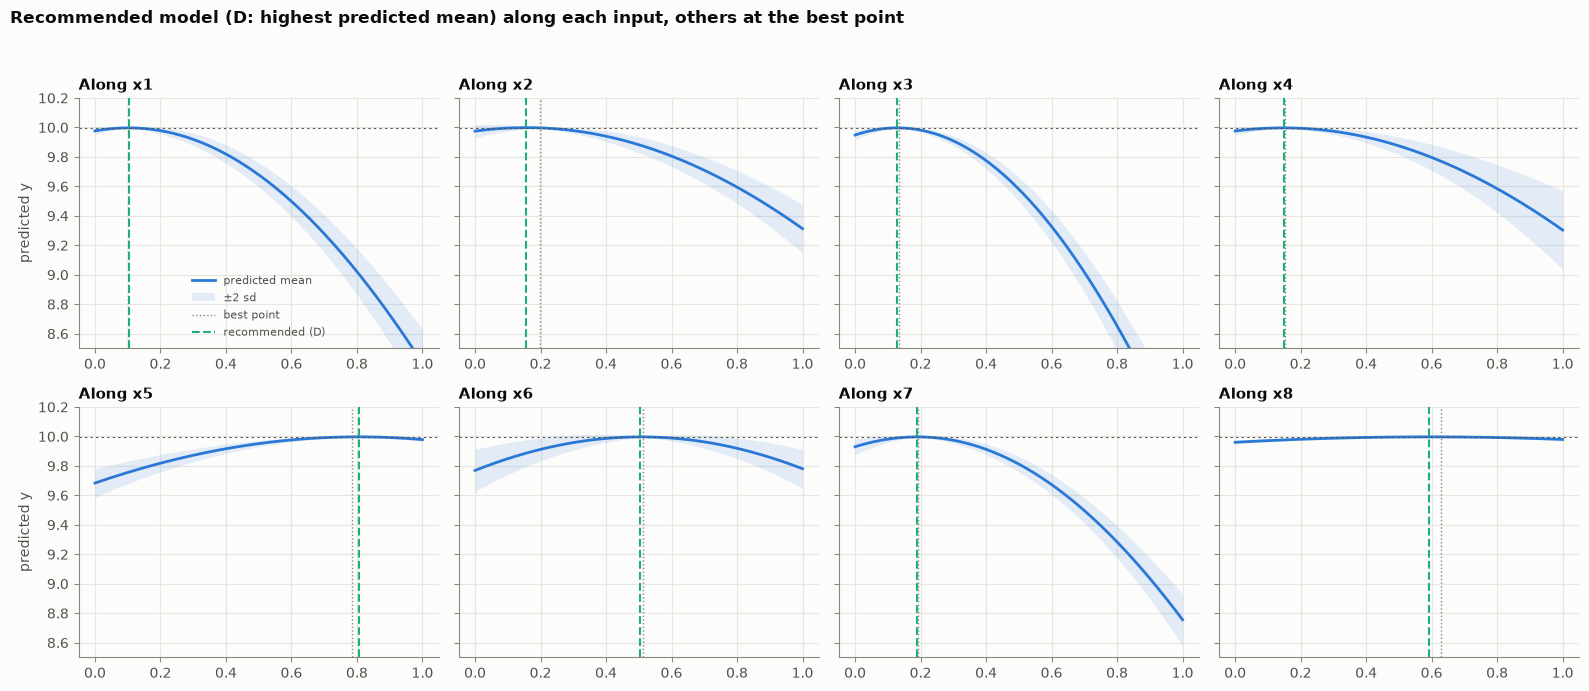

In [7]:
# Fig 3: slices through the best point, recommended model
xD = cands["D: highest predicted mean, full domain"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
xs = np.linspace(0, 1, 200)
for j, ax in enumerate(axes.flat):
    Z = np.tile(xb, (len(xs), 1)); Z[:, j] = xs
    m, s = pmean(Z), psd(Z)
    ax.plot(xs, m, color=PAL[0], lw=2, label="predicted mean")
    ax.fill_between(xs, m - 2 * s, m + 2 * s, color=PAL[0], alpha=0.12, lw=0, label="±2 sd")
    ax.axvline(xb[j], color=MUTED, lw=1, ls=":", label="best point")
    ax.axvline(xD[j], color=PAL[2], lw=1.5, ls="--", label="recommended (D)")
    ax.axhline(y[best], color=INK2, lw=0.8, ls=(0, (2, 3)))
    ax.set_title(f"Along x{j + 1}"); ax.set_ylim(8.5, 10.2)
axes[0, 0].set_ylabel("predicted y"); axes[1, 0].set_ylabel("predicted y")
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower center", labelcolor=INK2)
fig.suptitle("Recommended model (D: highest predicted mean) along each input, others at the best point",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))

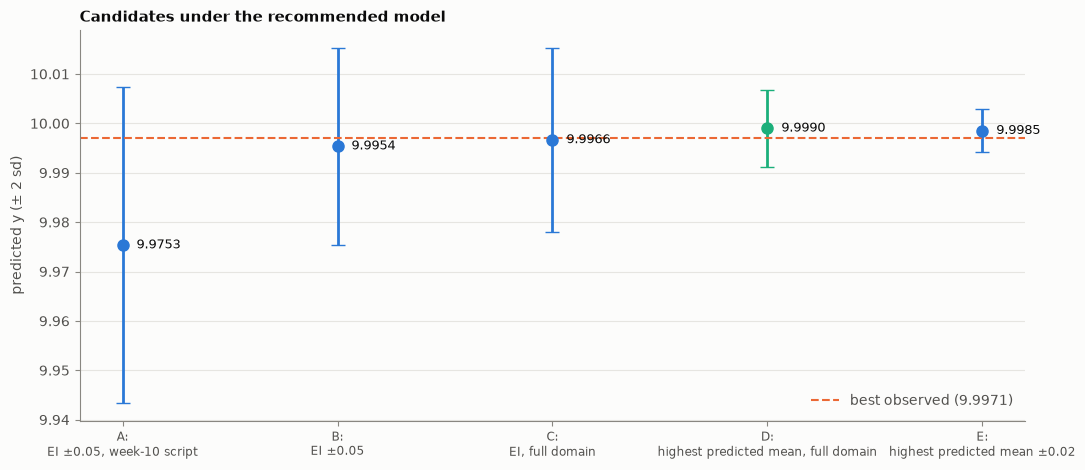

In [8]:
# Fig 4: candidates, predicted y with ±2 sd
fig, ax = plt.subplots(figsize=(11, 4.8))
names = list(cands)
for k, name in enumerate(names):
    m, s = pmean(cands[name])[0], psd(cands[name])[0]
    col = PAL[2] if name.startswith("D") else PAL[0]
    ax.errorbar(k, m, yerr=2 * s, fmt="o", color=col, ecolor=col, elinewidth=2, capsize=5, ms=8)
    ax.annotate(f"{m:.4f}", (k, m), xytext=(10, 0), textcoords="offset points", fontsize=9, color=INK, va="center")
ax.axhline(y[best], color=PAL[1], lw=1.5, ls="--", label=f"best observed ({y[best]:.4f})")
ax.set_xticks(range(len(names)))
ax.set_xticklabels([nm.split(":")[0] + ":\n" + nm.split(":")[1].strip() for nm in names], fontsize=8.5)
ax.set_ylabel("predicted y (± 2 sd)")
ax.set_title("Candidates under the recommended model")
ax.legend(frameon=False, loc="lower right", labelcolor=INK2)
ax.grid(axis="x", visible=False)
fig.tight_layout()